# Decision Tree — Thyroid Classification

A depth-3 tree, kept small so the whole model can be read off the page.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

CSV = "../dataset/hypothyroid.csv"
FEATURES = ["age", "sex", "TSH", "TT4", "T4U", "FTI"]
TARGET = "binaryClass"
CLASS_NAMES = ["negative", "hypothyroid"]
RANDOM_STATE = 42

## Load and clean

In [2]:
# Same cleaning as thyroid.ipynb section 3.
df = pd.read_csv(CSV, na_values="?")[FEATURES + [TARGET]]

known = df["sex"].notna()
df.loc[known, "sex"] = LabelEncoder().fit_transform(df.loc[known, "sex"])
df["sex"] = df["sex"].astype(float)

# LabelEncoder puts "N" first, and "N" is the hypothyroid group, so flip it.
df[TARGET] = 1 - LabelEncoder().fit_transform(df[TARGET])

clean = df[~(df["age"] > 120)].drop_duplicates()
X = clean[FEATURES]
y = clean[TARGET]
print(f"{len(clean)} patients, {y.sum()} hypothyroid ({100 * y.mean():.2f}%)")
clean.head()

3658 patients, 291 hypothyroid (7.96%)


,age,sex,TSH,TT4,T4U,FTI,binaryClass
0,41.0,0.0,1.30,125.0,1.14,109.0,0
1,23.0,0.0,4.10,102.0,NaN,NaN,0
2,46.0,1.0,0.98,109.0,0.91,120.0,0
3,70.0,0.0,0.16,175.0,NaN,NaN,0
4,70.0,0.0,0.72,61.0,0.87,70.0,0


## Split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"train {len(X_train)}, test {len(X_test)}")

train 2926, test 732


## Train

In [4]:
tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are con

## Evaluate

In [5]:
pred = tree.predict(X_test)

print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))
print("confusion matrix [rows = actual]")
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

    negative     0.9985    0.9837    0.9910       674
 hypothyroid     0.8382    0.9828    0.9048        58

    accuracy                         0.9836       732
   macro avg     0.9184    0.9832    0.9479       732
weighted avg     0.9858    0.9836    0.9842       732

confusion matrix [rows = actual]
[[663  11]
 [  1  57]]


## The model, in full

`class_weight="balanced"` makes the leaf `value` pairs weighted counts rather than raw patient
counts, so read the majority class rather than the absolute numbers.

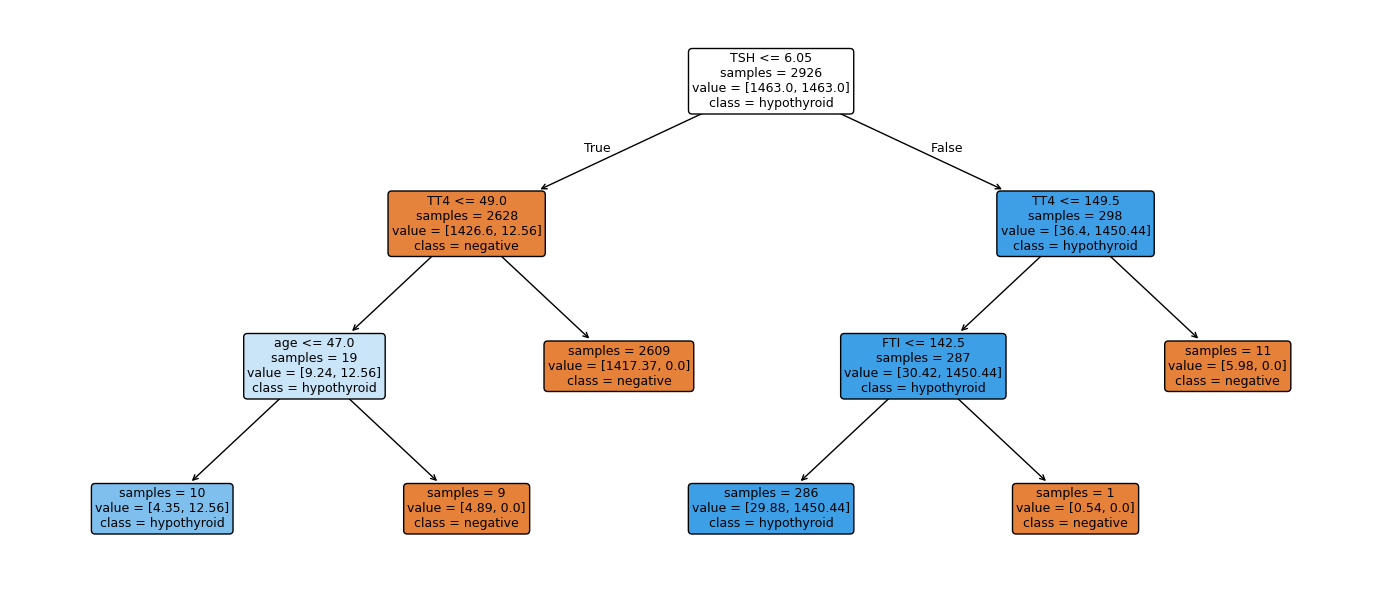

In [6]:
plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=FEATURES, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9, impurity=False, precision=2)
plt.tight_layout()
plt.show()

In [7]:
print(export_text(tree, feature_names=FEATURES, decimals=2))

|--- TSH <= 6.05
|   |--- TT4 <= 49.00
|   |   |--- age <= 47.00
|   |   |   |--- class: 1
|   |   |--- age >  47.00
|   |   |   |--- class: 0
|   |--- TT4 >  49.00
|   |   |--- class: 0
|--- TSH >  6.05
|   |--- TT4 <= 149.50
|   |   |--- FTI <= 142.50
|   |   |   |--- class: 1
|   |   |--- FTI >  142.50
|   |   |   |--- class: 0
|   |--- TT4 >  149.50
|   |   |--- class: 0

